# G4 BF16 matmul: 기초 CUDA부터 단계별 최적화

**`D = A @ B`**, BF16 입력 · FP32 출력 · FP32 내부 누산. C 입력, alpha/beta 산술, bias, activation은 없다.

기본 모드는 저장된 측정값의 **로컬 분석**이다. GPU 없이 표와 그래프를 볼 수 있다.
`RUN_GPU=True`로 바꾸면 현재 Colab G4에서 직접 작성한 CUDA 커널을 빌드하고 cuBLASLt와 비교한다.
런타임의 생성·종료는 이 노트북이 수행하지 않는다. [구현·사용법](../tensor_core_gemm_bf16/README.md) · [실험 기록](../tensor_core_gemm_bf16/WORKLOG.md)

In [1]:
RUN_GPU = False
RUN_CHECKS = True                 # RUN_GPU=True일 때 전체 GPU 검증
SEED = 42
ROUNDS = 5
RESULT_SET = 'final-fixed'         # 저장 결과: final-fixed / final-auto

## 1. 프로젝트와 데이터 경로

로컬에서는 저장소 루트 또는 notebooks 폴더에서 실행한다. Colab에서 소스 폴더가 없으면,
`RUN_GPU=True`일 때 이 작업의 `source-g4-bf16.tgz`를 업로드할 수 있다. 저장 결과 분석에는
저장소의 `tensor_core_gemm_bf16/artifacts/2026-10-17-g4/`가 필요하다.

In [2]:
from pathlib import Path
import json, sys, subprocess, tarfile
from IPython.display import display, Markdown, Image

candidates = [Path.cwd(), *Path.cwd().parents, Path('/content'), Path('/content/tensor2silicon')]
ROOT = next((p / 'tensor_core_gemm_bf16' for p in candidates
             if (p / 'tensor_core_gemm_bf16/Makefile').is_file()), None)
if ROOT is None and RUN_GPU:
    from google.colab import files
    uploaded = files.upload()
    archives = [Path(name) for name in uploaded if name.endswith(('.tgz', '.tar.gz'))]
    if len(archives) != 1:
        raise RuntimeError('source-g4-bf16.tgz 하나를 업로드하세요.')
    with tarfile.open(archives[0]) as archive:
        archive.extractall('/content', filter='data')
    ROOT = Path('/content/tensor_core_gemm_bf16')
if ROOT is None:
    raise RuntimeError('tensor_core_gemm_bf16 폴더가 있는 저장소에서 노트북을 실행하세요.')
ROOT = ROOT.resolve()
RAW_DIR = ROOT / 'artifacts/2026-10-17-g4' / RESULT_SET
sys.path.insert(0, str(ROOT))
from check_layout import check
print('Project:', ROOT)
print('CPU shared-layout/rasterization:', check(), 'PASS')
print('Data:', RAW_DIR)

Project: /home/jake/tensor2silicon/tensor_core_gemm_bf16
CPU shared-layout/rasterization: 180 PASS
Data: /home/jake/tensor2silicon/tensor_core_gemm_bf16/artifacts/2026-10-17-g4/final-fixed


## 2. 현재 G4에서 재실행 (선택)

현재 GPU가 SM120/BF16인지 먼저 확인한다. 입력 생성·변환·할당·전송·reference·warmup·
Graph capture는 측정에서 제외한다. 커널과 cuBLAS 모두 CUDA Graph를 사용하며, 같은
행렬을 반복 재사용한다. 아래 셀은 GPU 모드에서만 실행된다.

저장된 제어 실험의 코어 클럭 목표는 2100 MHz다. 이 셀은 클럭 설정을 변경하지 않는다.
재현할 때는 README의 클럭 설정·복원 명령과 실제 telemetry를 함께 확인한다.

In [3]:
if RUN_GPU:
    import torch
    props = torch.cuda.get_device_properties(0)
    assert torch.cuda.get_device_capability(0) == (12, 0), props
    assert torch.cuda.is_bf16_supported()
    print(props)
    build = subprocess.run(['make'], cwd=ROOT, capture_output=True, text=True)
    if build.returncode:
        print(build.stdout, build.stderr)
        print((ROOT / 'build/resources.log').read_text()[-6000:])
        raise RuntimeError('CUDA build failed')
    RAW_DIR = ROOT / 'results/notebook'
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    if RUN_CHECKS:
        with (RAW_DIR / 'checks.jsonl').open('w') as log:
            subprocess.run([str(ROOT / 'build/bf16_gemm'), 'check'], cwd=ROOT, stdout=log, check=True)
        summary = [json.loads(s) for s in (RAW_DIR / 'checks.jsonl').read_text().splitlines()][-1]
        assert summary['failed'] == 0, summary
        display(summary)
    with (RAW_DIR / 'driver.log').open('w') as log:
        subprocess.run([sys.executable, str(ROOT / 'benchmark_selected.py'), '--seed', str(SEED),
                        '--rounds', str(ROUNDS), '--include-stages', '--output', str(RAW_DIR)],
                       cwd=ROOT, stdout=log, stderr=subprocess.STDOUT, check=True)
    print('Saved:', RAW_DIR)
else:
    print('Saved results only; no GPU calls or runtime allocation.')

Saved results only; no GPU calls or runtime allocation.


## 3. 정확도를 통과한 원시 결과 읽기

reference는 같은 BF16 값을 FP32로 변환한 pedantic FP32 GEMM이다. 작은 shape에서는
CPU FP64 reference도 검증한다. 전체 출력의 정규화 최대 오차와 상대 L2 오차가 모두
1e-4 이하이고 NaN/Inf가 없어야 한다. 분석기는 실패 기록이나 측정 전·후 검사가 빠진
파일을 거부한다. 아래 값은 각 seed의 **5회 중앙값**이며 두 seed의 결과를 별도로 보여 준다.

In [4]:
import pandas as pd
from analyze import summarize
paths = sorted(RAW_DIR.glob('selected-*.jsonl'))
if not paths:
    raise FileNotFoundError(f'No saved results: {RAW_DIR}')
rows = summarize(paths)
df = pd.DataFrame(rows)
policy = json.loads((ROOT / 'selected.json').read_text())
chosen = {c['size']: c['variant'] for c in policy['conditions']}
native = df[df.apply(lambda r: r['variant'] == chosen[r['size']], axis=1)].copy()
assert not native.empty
assert native['full_output_pass'].all()
assert (native['samples'] >= ROUNDS).all()
display(native[['size', 'seed', 'variant', 'group', 'median_ms', 'tflops', 'cublas_ratio', 'samples']]
        .sort_values(['size', 'seed']).round(5))

,size,seed,variant,group,median_ms,tflops,cublas_ratio,samples
69,128,42,t32x32k64w32x32s3,8,0.00228,1.84077,0.94200,5
15,128,20261017,t32x32k64w32x32s3,8,0.00228,1.84090,0.94565,5
85,256,42,t32x32k64w32x32s4,8,0.00308,10.89996,1.11003,5
31,256,20261017,t32x32k64w32x32s4,8,0.00308,10.89883,1.11231,5
100,512,42,t64x32k64w32x32s4,8,0.00491,54.66850,0.96028,5
46,512,20261017,t64x32k64w32x32s4,8,0.00491,54.66137,0.96032,5
55,1024,42,p128x64_s3,8,0.01345,159.64617,0.89634,5
1,1024,20261017,p128x64_s3,8,0.01344,159.77730,0.89037,5
71,2048,42,q128x64_s2,8,0.06572,261.40944,1.07075,5
17,2048,20261017,q128x64_s2,8,0.06553,262.18305,1.07377,5


## 4. 크기별 성능

cuBLAS 대비 비율은 같은 입력·seed·실행에서 측정한 cuBLAS 시간을 native 시간으로
나눈 값이다. 1.0을 넘으면 native가 빠르다. 이 비율은 이론 peak나 하드웨어 사용률이 아니다.

/home/jake/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-0mydnmep because there was an issue with the default path (/home/jake/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


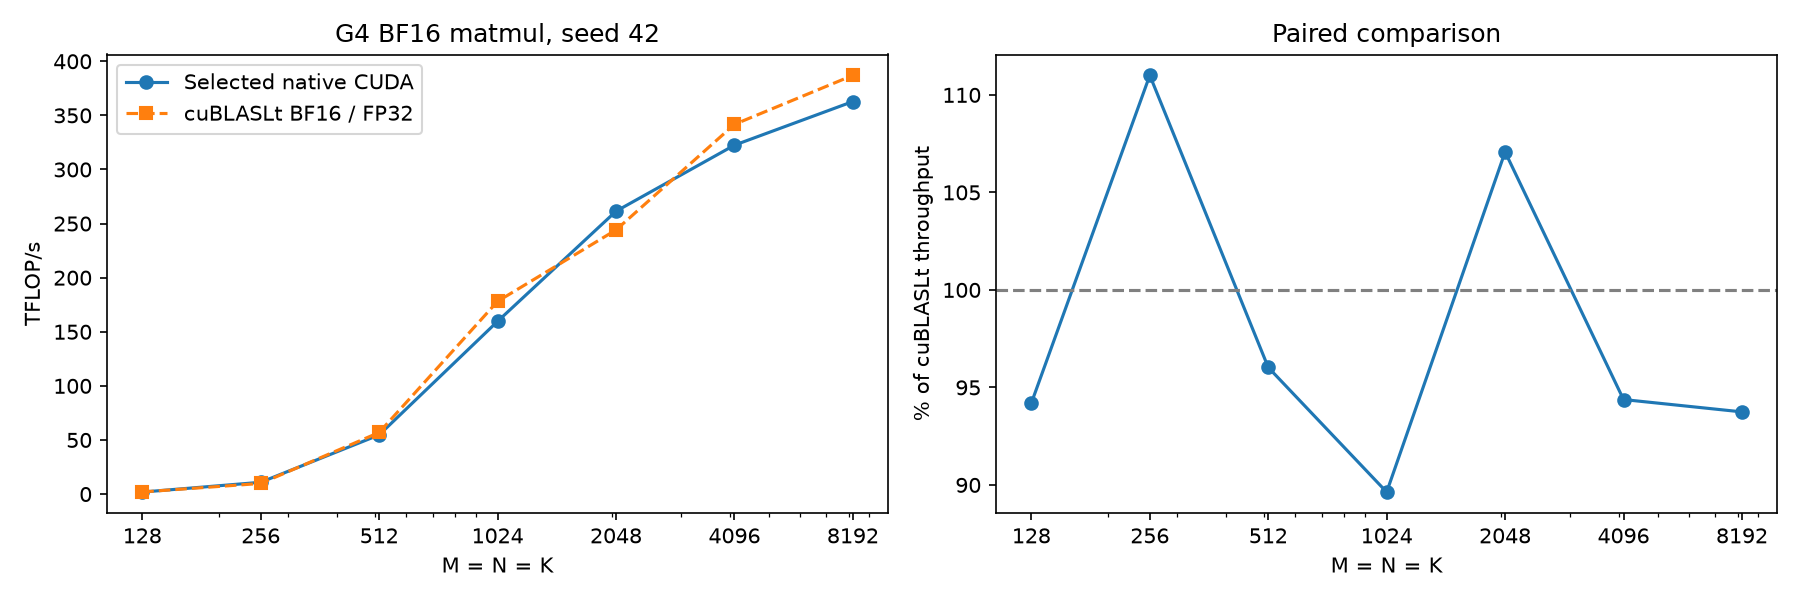

In [5]:
import matplotlib.pyplot as plt
import io
plot_seed = SEED if SEED in set(native['seed']) else int(native['seed'].min())
n = native[native['seed'] == plot_seed].sort_values('size')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(n['size'], n['tflops'], 'o-', label='Selected native CUDA')
axes[0].plot(n['size'], 2*n['size']**3/n['cublas_ms']/1e9, 's--', label='cuBLASLt BF16 / FP32')
axes[0].set(xscale='log', xlabel='M = N = K', ylabel='TFLOP/s', title=f'G4 BF16 matmul, seed {plot_seed}')
axes[0].set_xticks(n['size'], [str(x) for x in n['size']]); axes[0].legend()
axes[1].plot(n['size'], 100*n['cublas_ratio'], 'o-')
axes[1].axhline(100, color='gray', linestyle='--')
axes[1].set(xscale='log', xlabel='M = N = K', ylabel='% of cuBLASLt throughput', title='Paired comparison')
axes[1].set_xticks(n['size'], [str(x) for x in n['size']])
fig.tight_layout()
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=150); plt.close(fig)
display(Image(data=buf.getvalue()))

## 5. 4096에서 단계별 비교

WMMA → SMEM 재사용 → 직접 MMA/LDMATRIX → cp.async → fragment 더블 버퍼링 → 최종 설정.
모든 기법이 항상 빨라지지는 않는다. 기본 fragment 더블 버퍼링이나 일부 출력 경로가
느려진 경우도 원시 기록에 남아 있다. 단계 2→3에서는 타일도 함께 바뀐다.

,median_ms,tflops,cublas_ratio,samples
variant,,,,
s1_wmma_global,3.01976,45.51321,0.13321,5
s2_wmma_smem,1.48936,92.28042,0.27008,5
s3_mma_ldmatrix,0.73846,186.11535,0.54471,5
s4_async,0.46350,296.52297,0.86785,5
s5_frag_double,0.47784,287.62844,0.84181,5
q128_s2,0.42621,322.47004,0.94379,5
cublas,0.40225,341.67683,1.00000,5


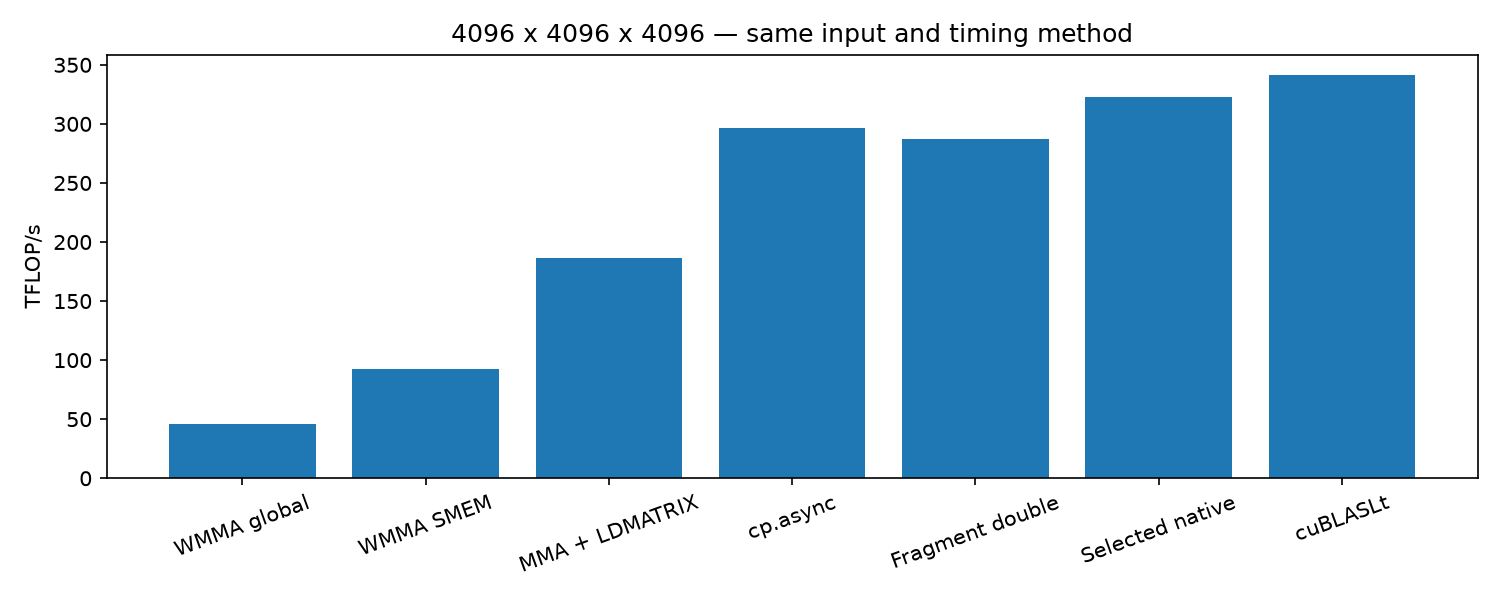

In [6]:
stages = ['s1_wmma_global', 's2_wmma_smem', 's3_mma_ldmatrix', 's4_async', 's5_frag_double', chosen[4096], 'cublas']
labels = ['WMMA global', 'WMMA SMEM', 'MMA + LDMATRIX', 'cp.async', 'Fragment double', 'Selected native', 'cuBLASLt']
part = df[(df['size'] == 4096) & (df['seed'] == plot_seed)].set_index('variant')
available = [(key, label) for key, label in zip(stages, labels) if key in part.index]
display(part.loc[[key for key, _ in available], ['median_ms', 'tflops', 'cublas_ratio', 'samples']].round(5))
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar([label for _, label in available], [part.loc[key, 'tflops'] for key, _ in available])
ax.set(ylabel='TFLOP/s', title='4096 x 4096 x 4096 — same input and timing method')
ax.tick_params(axis='x', rotation=20); fig.tight_layout()
buf = io.BytesIO(); fig.savefig(buf, format='png', dpi=150); plt.close(fig)
display(Image(data=buf.getvalue()))

## 6. 프로파일러와 남은 차이

Nsight Compute 값은 별도 프로파일링 실행에서 수집했다. 프로파일러가 측정한 시간과
위 일반 벤치마크 시간을 섞지 않는다. Tensor elapsed 카운터, 실제 클럭, 실행 명령 수,
register/spill과 stall을 함께 본다. 수집되지 않은 카운터는 빈 값으로 표시한다.

In [7]:
profile_path = ROOT / 'artifacts/2026-10-17-g4/profile-summary.json'
if profile_path.exists():
    profiles = pd.DataFrame(json.loads(profile_path.read_text()))
    cols = [c for c in ['source', 'kernel', 'tensor_elapsed_pct', 'registers_per_thread',
                        'instructions', 'spilling_instructions', 'profile_ms'] if c in profiles]
    display(profiles[cols])
else:
    print('Saved profile summary is not present in this checkout.')

,source,kernel,tensor_elapsed_pct,registers_per_thread,instructions,spilling_instructions,profile_ms
0,/content/bf16-g4/profiles-final/cublas-4096.me...,void Kernel2<cutlass_80_tensorop_s16816gemm_bf...,84.868075,218.0,96772096.0,0.0,0.413184
1,/content/bf16-g4/profiles-final/cublas-8192.me...,void Kernel2<cutlass_80_tensorop_s16816gemm_bf...,95.883574,218.0,758284288.0,0.0,2.860288
2,/content/bf16-g4/profiles-final/q128_s2-4096.m...,"void bf16Pipeline<128, 128, 32, 64, 64, 2, 1, ...",80.106084,192.0,120815616.0,0.0,0.440832
3,/content/bf16-g4/profiles-final/q128_s2-8192.m...,"void bf16Pipeline<128, 128, 32, 64, 64, 2, 1, ...",89.919525,192.0,961413120.0,0.0,3.051072
4,/content/bf16-g4/profiles-final/s4_async-4096....,"void bf16Pipeline<128, 128, 32, 64, 32, 3, 1, ...",73.721561,126.0,173711360.0,0.0,0.478240
